# Comparación de ciclos de descarga de una batería

## 1. Introducción

En esta parte se estudiará y analizará el comportamiento de la batería ion-litio B0005, basándonos en 3 descargas realizadas en diferentes etapas de su vida útil durante la realización del experimento de ciclos de carga y descarga consecutivos:
1. Etapa inicial: descarga 1 (poco uso)
2. Etapa intermedia: descarga 80 (mayor uso)
3. Etapa avanzada : descarga 160 (mucho uso)

El objetivo es observar posibles cambios asociados al envejecimiento de la bateria analizando cómo cambian sus señales eléctricas y la temperatura con el paso de los ciclos.

Finalmente, se analizarán las diferencias observadas para comprobar si pueden estar relacionadas con la degradación de la batería o con las condiciones en las que se han realizado los ensayos.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Busco la carpeta de datos
carpeta_datos = Path("../datos_procesados")

if not carpeta_datos.exists():
    carpeta_datos = Path("datos_procesados")

# Leer los archivos de la carpeta
mediciones = pd.read_csv(carpeta_datos / "mediciones.csv")
resumen_ciclos = pd.read_csv(carpeta_datos / "resumen_ciclos.csv")

# Compruebo que los datos se han cargado correctamente
print("Dimensiones de mediciones:", mediciones.shape)
print("Dimensiones de resumen:", resumen_ciclos.shape)

display(mediciones.head())
display(resumen_ciclos.head())


Dimensiones de mediciones: (591458, 8)
Dimensiones de resumen: (338, 8)


,bateria,registro_original,tipo,numero_tipo,tiempo_s,tension_V,corriente_A,temperatura_C
0,B0005,1,charge,1,0.000,3.873017,-0.001201,24.655358
1,B0005,1,charge,1,2.532,3.479394,-4.030268,24.666480
2,B0005,1,charge,1,5.500,4.000588,1.512731,24.675394
3,B0005,1,charge,1,8.344,4.012395,1.509063,24.693865
4,B0005,1,charge,1,11.125,4.019708,1.511318,24.705069


,bateria,registro_original,tipo,numero_tipo,numero_descarga,duracion_s,duracion_activa_s,capacidad_Ah
0,B0005,1,charge,1,NaN,7597.875,1875.015,NaN
1,B0005,2,discharge,1,1.0,3690.234,3311.234,1.856487
2,B0005,3,charge,2,NaN,10516.000,4416.984,NaN
3,B0005,4,discharge,2,2.0,3672.344,3293.125,1.846327
4,B0005,5,charge,3,NaN,10484.547,4388.656,NaN


## 2.  Selección de las descargas 1, 80, 160

Del conjunto total de mediciones de la batería B0005, seleccionamos únicamente las correspondientes a las descargas 1, 80 y 160 para poder comparar su comportamiento en diferentes etapas de uso.

In [ ]:
# Seleccionar las descargas 1, 80 y 160 del conjunto 
descarga_1 = mediciones[(mediciones["tipo"] == "discharge") & (mediciones["numero_tipo"] == 1)]

descarga_80 = mediciones[(mediciones["tipo"] == "discharge") & (mediciones["numero_tipo"] == 80)]

descarga_160 = mediciones[(mediciones["tipo"] == "discharge") & (mediciones["numero_tipo"] == 160)]

# número de mediciones de cada descarga
print("Descarga 1:", len(descarga_1), "mediciones")
print("Descarga 80:", len(descarga_80), "mediciones")
print("Descarga 160:", len(descarga_160), "mediciones")


Descarga 1: 197 mediciones
Descarga 80: 330 mediciones
Descarga 160: 299 mediciones


## 3. Comparar cómo cambia la tensión en las 3 descargas

Se representa la evolución de la tensión en función del tiempo para las descargas 1, 80 y 160.

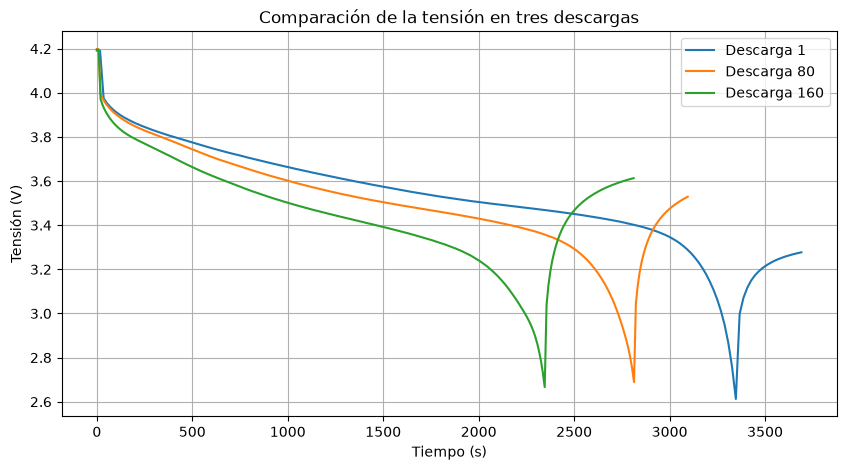

In [ ]:
# Tiempo transcurrido desde el inicio de cada descarga
# para que todas empiecen en el instante 0 les resto el primer instante
t1 = descarga_1["tiempo_s"] - descarga_1["tiempo_s"].iloc[0]
t80 = descarga_80["tiempo_s"] - descarga_80["tiempo_s"].iloc[0]
t160 = descarga_160["tiempo_s"] - descarga_160["tiempo_s"].iloc[0]


plt.figure(figsize=(10, 5))

plt.plot(t1, descarga_1["tension_V"], label="Descarga 1")
plt.plot(t80, descarga_80["tension_V"], label="Descarga 80")
plt.plot(t160, descarga_160["tension_V"], label="Descarga 160")

plt.xlabel("Tiempo (s)")
plt.ylabel("Tensión (V)")
plt.title("Comparación de la tensión en tres descargas")
plt.legend()
plt.grid(True)
plt.show()



### Interpretación de la gráfica

En la gráfica se observa que las tres descargas presentan un comportamiento similar: inicialmente la tensión disminuye rápidamente y después continúa descendiendo de forma progresiva hasta alcanzar un mínimo.

Se observa una tendencia descendente de la tensión. La descarga 160 alcanza antes los valores bajos de tensión, mientras que la descarga 1 los mantiene durante más tiempo.

A medida que aumenta el número de descargas, la batería alcanza antes los valores bajos de tensión. 

Finalmente, se observa una recuperación de la tensión al final de las tres curvas, probablemente debida a la interrupción de la corriente de descarga.


## 4. Comparación de la Temperatura en las 3 descargas

Se representa la evolución de la temperatura durante las tres descargas seleccionadas.

El objetivo es comprobar si existen diferencias en el calentamiento de la batería entre las distintas etapas de uso.

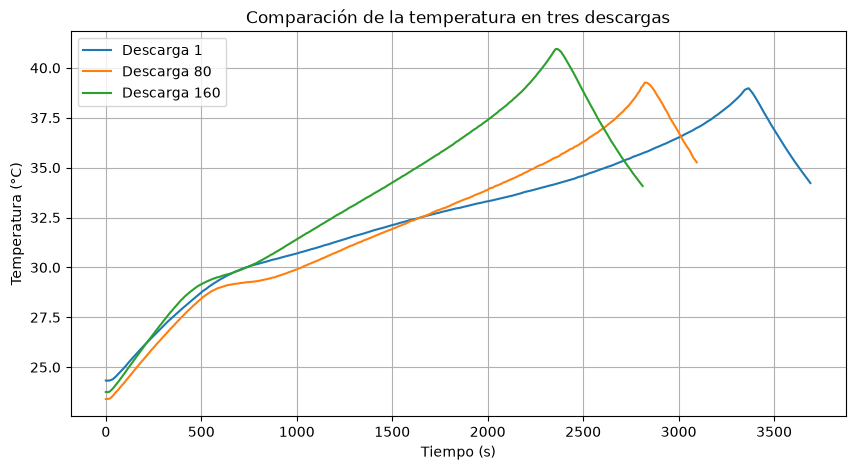

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(t1, descarga_1["temperatura_C"], label="Descarga 1")
plt.plot(t80, descarga_80["temperatura_C"], label="Descarga 80")
plt.plot(t160, descarga_160["temperatura_C"], label="Descarga 160")

plt.xlabel("Tiempo (s)")
plt.ylabel("Temperatura (°C)")
plt.title("Comparación de la temperatura en tres descargas")
plt.legend()
plt.grid(True)
plt.show()



### Interpretación de la gráfica

En la gráfica se observa que la temperatura aumenta progresivamente durante las tres descargas, partiendo de valores iniciales similares.

La descarga 1 alacanza una temperatura máxima aproximada de 39 °C, la descarga 80 de 39,3 °C y la descarga 160 de 41 °C. 
Por tanto, se observa un aumento de la temperatura máxima según avanza el número de descarga.

La descarga 160 alcanza su temperatura máxima mucho más rápido que las descargas 1 y 80.

Al final de las tres curvas se observa una disminución de la temperatura, probablemente relacionada con la interrupción de la corriente de descarga.

Se puede concluir que a medida que se avanza en el experimento, la bateria tiende a calentarse más rápido y llegando a picos máximos en un tiempo menor.


## 5. Comparación de la corriente para las 3 descargas 

Para comprobar si las tres descargas se han realizado en condiciones similares, se representa la evolución de la corriente en función del tiempo.

Así se logrará observar si las diferencias en la duración, la tensión y la temperatura podrían estar relacionadas con la corriente aplicada durante cada descarga.


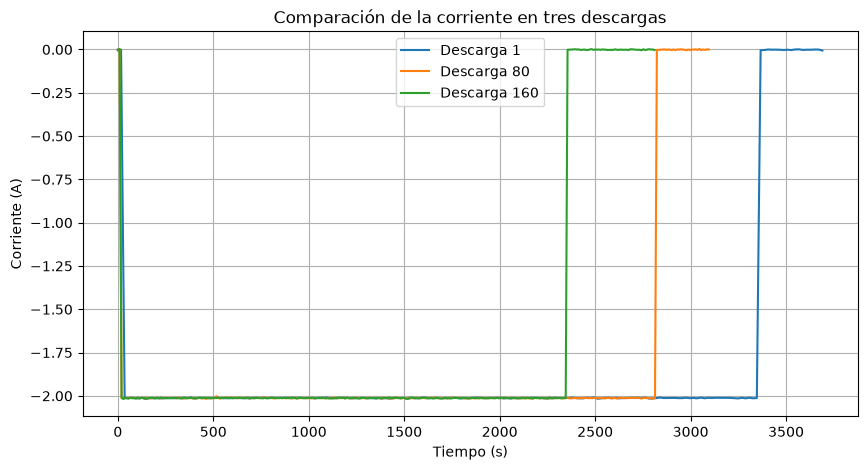

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(t1, descarga_1["corriente_A"], label="Descarga 1")
plt.plot(t80, descarga_80["corriente_A"], label="Descarga 80")
plt.plot(t160, descarga_160["corriente_A"], label="Descarga 160")

plt.xlabel("Tiempo (s)")
plt.ylabel("Corriente (A)")
plt.title("Comparación de la corriente en tres descargas")
plt.legend()
plt.grid(True)
plt.show()



### Interpretación de la gráfica

En la gráfica se observa que las tres descargas mantienen una corriente constante de -2 A.

En el momento en el que se interrumpe la descarga, la descarga 1 es la que mantiene la corriente durante más tiempo, seguida de la descarga 80 y, finalmente, de la descarga 160.

Esto nos indica que las tres descargas se han realizado con condiciones de corriente similares, por lo que las diferencias observadas en la duración y en la tensión no se deben a la corriente aplicada.


## 6. Cálculo de los valores numéricos y tabla comparativa

Para comparar las tres descargas de forma numérica, se calculan la duración, las tensiones inicial y final, la variación de tensión, la temperatura máxima, el aumento de temperatura y la corriente media(para comprobar que las condiciones de descarga son similares).

Para estos cálculos se ha considerado la fase activa de descarga, utilizando el mismo criterio empleado en la preparación de los datos: una corriente con valor absoluto igual o superior a 0,5 A.

In [ ]:
# Creo la tabla comparativa de las tres descargas

# creo una lista para ir guardando los valores de cada descarga
resultados = []

# para cada una de las tres descargas resgistro una fila con sus valores y la guardo en resultados
for numero, datos in [(1, descarga_1), (80, descarga_80), (160, descarga_160)]:

    # Seleccionar las mediciones de la descarga activa
    activa = datos[np.abs(datos["corriente_A"]) >= 0.5]

    # Obtengo datos de resumen_ciclos de la descarga 
    resumen = resumen_ciclos[
        (resumen_ciclos["tipo"] == "discharge") &
        (resumen_ciclos["numero_descarga"] == numero)
    ].iloc[0]

    # Cálculo de las tensiones
    v_inicial = activa["tension_V"].iloc[0]
    v_final = activa["tension_V"].iloc[-1]
    diferencia_v = v_inicial - v_final

    # Cálculo de las temperaturas
    temp_inicial = activa["temperatura_C"].iloc[0]
    temp_maxima = activa["temperatura_C"].max()
    aumento_temp = temp_maxima - temp_inicial

    # Guardar los resultados
    resultados.append({
        "Descarga": numero,
        "Duración total (s)": round(resumen["duracion_s"], 2),
        "Duración activa (s)": round(resumen["duracion_activa_s"], 2),
        "Tensión inicial (V)": round(v_inicial, 2),
        "Tensión final (V)": round(v_final, 2),
        "Variación tensión (V)": round(diferencia_v, 2),
        "Temperatura máxima (°C)": round(temp_maxima, 2),
        "Aumento temperatura (°C)": round(aumento_temp, 2),
        "Corriente media (A)": round(activa["corriente_A"].mean(), 2)
    })

# Mostrar la tabla 
tabla_comparativa = pd.DataFrame(resultados)
display(tabla_comparativa)


,Descarga,Duración total (s),Duración activa (s),Tensión inicial (V),Tensión final (V),Variación tensión (V),Temperatura máxima (°C),Aumento temperatura (°C),Corriente media (A)
0,1,3690.23,3311.23,3.97,2.61,1.36,38.90,14.52,-2.01
1,80,3095.09,2794.05,3.99,2.69,1.31,39.11,15.69,-2.01
2,160,2811.48,2326.22,3.97,2.67,1.30,40.81,17.04,-2.01


In [9]:
# Calcular la reducción de duración entre la descarga 1 y la 160

duracion_1 = tabla_comparativa["Duración activa (s)"].iloc[0]
duracion_160 = tabla_comparativa["Duración activa (s)"].iloc[2]

reduccion = (duracion_1 - duracion_160) / duracion_1 * 100

print("Reducción de duración:", round(reduccion, 2), "%")


Reducción de duración: 29.75 %



### Interpretación de los resultados

Se observa que la duración activa de la batería disminuye con el número de descargas.

La descarga 1 tiene una duración activa de 3311,23 segundos, mientras que la descarga 80 dura 2794,05 segundos y la descarga 160 dura 2326,22 segundos. 

En cuanto a la tensión, las tres descargas comienzan con valores similares aproximadamente 4 V, y terminan con tensiones 2,61 , 2,69 y 2,67 V. Pero, la descarga 160 alcanza estos valores bajos en menos tiempo.

También se aprecian las diferencias antes vistas en la temperatura. La descarga 1 alcanza una temperatura máxima de 38,90 °C, mientras que la descarga 160 llega a 40,81 °C. 

Por otro lado, las tres descargas presentan una corriente media de -2,01 A durante la fase activa, lo que indica que se han realizado con condiciones de corriente similares, por tanto las diferencias de duración no se deben a la corriente aplicada.

Estos resultados muestran una reducción de la duración activa y cambios en la temperatura de la batería, compatibles con un posible proceso de degradación. 
No obstante, para poder confirmar esto último sería necesario contrastar los resultados con la evolución de la capacidad de la bateria.


## 7. Relacción entre la duración activa y la capacidad de la batería

Se realiza un estudio entre la relación de el tiempo durante el cual la batería se está descargando con una corriente de -2.01 A (duración activa) y la cantidad de carga eléctrica que puede dar durante la descarga (capacidad), esto se hace para las 3 descargas.


In [12]:
# Seleccionar la capacidad de nuestras tres descargas
capacidades = resumen_ciclos[
    (resumen_ciclos["tipo"] == "discharge") &
    (resumen_ciclos["numero_descarga"].isin([1, 80, 160]))
][["numero_descarga", "capacidad_Ah"]].sort_values("numero_descarga").reset_index(drop=True)

# Mostrar los valores
print("Capacidad de las tres descargas (Ah):")
display(capacidades.round(3))

# Calcular la reducción de capacidad de la descarga 1 a la 160
capacidad_1 = capacidades["capacidad_Ah"].iloc[0]
capacidad_160 = capacidades["capacidad_Ah"].iloc[-1]
reduccion_capacidad = (capacidad_1 - capacidad_160) / capacidad_1 * 100

print("Reducción de capacidad:", round(reduccion_capacidad, 2), "%")

Capacidad de las tres descargas (Ah):


,numero_descarga,capacidad_Ah
0,1.0,1.856
1,80.0,1.565
2,160.0,1.303


Reducción de capacidad: 29.79 %


Se puede observar que a medida que aumenta el número de descargas, la capacidad de la bateria para suministrar energía también disminuye con un porcentaje de disminución del 29,79% entre la primera y la última descarga.

Los valores de reducción activa(29.75%) y reducción de capacidad(29.79%), resultan ser simlares ya que es lógico que a menor capacidad, menor duración la batería permanece descargandose.

Estos resultados son compatibles con una pérdida de capacidad asociada al envejecimiento de la batería.